### Introduction

# Brice Turang: Hitter Development Plan (2024 baseline)

**What this project is:** An individual development plan (IDP) for one MLB hitter, built the way a player development (PD) analyst would build it: find his strength, find his biggest gap, pick one priority, set measurable goals, design a drill plan, and decide how to track progress.

**Development question:** For Brice Turang after the 2024 season, what is the #1 swing metric he should prioritize to improve his hitting, and how will we know it worked?

**The twist:** I write the plan using only data through the 2024 season, as if I worked in the Brewers' PD department that off-season. Then I test it against what actually happened in 2025 and 2026. Most development plans can't be checked; this one can.

**Who it's for:**
- **The player** needs one priority and a drill plan.
- **The hitting coach** needs the goals and how to measure them.
- **The PD director** needs the evidence and an honest result.

**How this notebook is organized:** Step 0 sets up the project. Steps 1–3 load, clean and benchmark the data. Steps 4–8 build the plan. Step 9 tests it on 2025–2026. Step 10 turns it into the one-pager, deck and README. Every step answers one question and ends with "What I found".

**Author:** Omar Morillo Aldana · Former college hitter, Driveline-certified hitting coach · [GitHub] · [LinkedIn]


### STEP 0 - THE SETUP 

In [1]:
from pathlib import Path
import pandas as pd 
import numpy as np




In [2]:
# STEP 0.2 — Project folder
print(Path.cwd())                   

PROJECT = Path("..").resolve()       
print(PROJECT.name)                 
assert PROJECT.name == "turang-hitter-development-plan", "Wrong folder: check where the notebook is"
assert any((PROJECT / "data" / "raw").glob("*.csv")), "No CSVs found in data/raw"

/Users/omarmorillo/Desktop/Baseball_Portfolio/turang-hitter-development-plan/notebooks
turang-hitter-development-plan


In [3]:
folders= ['data/raw', 'data/clean', 'notebooks', 'outputs/charts', 'deliverables']
for folder in folders:
    folder_path= PROJECT/folder
    folder_path.mkdir(parents=True, exist_ok=True)
    print(f"ready {folder_path}")

ready /Users/omarmorillo/Desktop/Baseball_Portfolio/turang-hitter-development-plan/data/raw
ready /Users/omarmorillo/Desktop/Baseball_Portfolio/turang-hitter-development-plan/data/clean
ready /Users/omarmorillo/Desktop/Baseball_Portfolio/turang-hitter-development-plan/notebooks
ready /Users/omarmorillo/Desktop/Baseball_Portfolio/turang-hitter-development-plan/outputs/charts
ready /Users/omarmorillo/Desktop/Baseball_Portfolio/turang-hitter-development-plan/deliverables


In [4]:
RAW= PROJECT/'data/raw'
raw_files= sorted(RAW.glob('*.csv'))
print(len(raw_files), ("CSV FILES"))
for f in raw_files:
    print(f.name)

24 CSV FILES
lb_bat_tracking_2023.csv
lb_bat_tracking_2024.csv
lb_bat_tracking_2025.csv
lb_bat_tracking_2026.csv
lb_batted_ball_2023.csv
lb_batted_ball_2024.csv
lb_batted_ball_2025.csv
lb_batted_ball_2026.csv
lb_exit_velocity_2023.csv
lb_exit_velocity_2024.csv
lb_exit_velocity_2025.csv
lb_exit_velocity_2026.csv
lb_expected_stats_2023.csv
lb_expected_stats_2024.csv
lb_expected_stats_2025.csv
lb_expected_stats_2026.csv
lb_swing_path_2023.csv
lb_swing_path_2024.csv
lb_swing_path_2025.csv
lb_swing_path_2026.csv
statcast_pitches_turang_2023.csv
statcast_pitches_turang_2024.csv
statcast_pitches_turang_2025.csv
statcast_pitches_turang_2026.csv


In [5]:
years= [2023,2024,2025,2026]
prefixes= ["statcast_pitches_turang",
    "lb_swing_path",
    "lb_bat_tracking",
    "lb_exit_velocity",
    "lb_expected_stats",
    "lb_batted_ball",]
expected = {f"{prefix}_{year}.csv" for prefix in prefixes for year in years}
actual = {f.name for f in raw_files}
print(len(expected), "EXPECTED FILES", "| Actual Files:", len(actual))
print("Missig:", expected-actual)
print("Extra:", actual-expected)

24 EXPECTED FILES | Actual Files: 24
Missig: set()
Extra: set()


In [6]:
# 0.6

readme= PROJECT/'README.md'
question= "For Brice Turang after the 2024 season, what is the #1 swing metric he should prioritize to improve his hitting, and how will we know it worked?"

if not readme.exists() or readme.read_text().strip() == "":
    readme.write_text(f"# Brice Turang: Hitter Development Plan\n\n**Development question:** {question}\n")
    print("README written")
else:
    print("README already has content, not overwritten")

print("README.md content:")
print(readme.read_text())

README already has content, not overwritten
README.md content:
# Brice Turang: Hitter Development Plan

**Development question:** For Brice Turang after the 2024 season, what is the #1 swing metric he should prioritize to improve his hitting, and how will we know it worked?



##### **What I found:** Setting up took more organizing than I expected: 24 Savant files had to be found, renamed and checked before any analysis could start. `pathlib` made the file paths manageable, but it also showed how easily a path can point to the wrong place: my notebook first looked at an empty copy of the project and found 0 files. I caught it because I printed the count instead of assuming it worked. After fixing the path, all 24 raw files were present with the expected names (nothing missing, nothing extra), and the README now opens with the development question. Step 1 loads this data and organizes it so it can show what Turang should work on.

## Step 1 

## Before we start: what Step 1 is about

Before I can say anything about Turang's swing, I need to know what data I'm working with and whether I can trust it. That's what this step is for. No analysis yet, just getting to know the data.

By the end of it, I want to be able to answer four things:

- How many pitches did Turang see each season, and how many of his swings were actually measured?
- When does the swing data start? (Bat tracking was turned on partway through 2023.)
- Who am I comparing him to? I'll build one table of every qualified MLB hitter, one row per hitter per season.
- What does each column mean? I'll write a short data dictionary so every number later on can be explained in plain words.

### Two kinds of data

I'm using two kinds of files from Baseball Savant. The first is Turang's pitch-by-pitch data: every pitch he saw, one row per pitch. That's where his swing lives, and it lets me see how his bat speed and swing path changed over time. The second is the league leaderboards, where each row is one hitter's full season. Those give me the benchmarks, so I can say where Turang ranks against the rest of MLB.

### Why the seasons play different roles

I am using only what was known at the time. So 2024 is the baseline, and every decision comes from it. 2023 is there for context, but the swing data only covers the second half of that season. 2025 and 2026 aren't used to make any decisions. They're the test: they show whether the plan would have worked.

### A few terms to know

- **Bat speed** Bat Speed: The velocity of the bat's sweet spot at the exact moment of contact with the ball, measured in miles per hour (mph). It represents a hitter's raw power potential.
- **Attack angle**  The vertical angle at which the bat's sweet spot is traveling at the moment of contact, measured in degrees relative to the ground. A positive angle means the bat is moving upward, while a negative angle means it is moving downward.(Desired angle: 9-12 degrees)
- **Competitive swings** are the swings Savant counts in its averages. It leaves out bunts, checked swings, and a hitter's slowest swings, so my raw averages will come out a bit lower than the leaderboard. I'll deal with that in Step 2.
- **Qualified hitters** are players with enough playing time to appear on the leaderboards. In 2023 the bar was lower, so that year has more hitters in it.

In [7]:
p24= pd.read_csv(RAW/"statcast_pitches_turang_2024.csv")
print(p24.head())
print(p24.shape)

  pitch_type   game_date  release_speed  release_pos_x  release_pos_z  \
0         FF  2024-09-29           93.0           2.41           5.98   
1         SI  2024-09-29           91.6           2.39           6.09   
2         SL  2024-09-29           82.1           2.59           5.90   
3         SL  2024-09-29           85.9           2.44           5.93   
4         SI  2024-09-29           91.2           2.14           6.10   

     player_name  batter  pitcher     events      description  ...  \
0  Turang, Brice  668930   656849  strikeout  swinging_strike  ...   
1  Turang, Brice  668930   656849        NaN             foul  ...   
2  Turang, Brice  668930   656849        NaN    called_strike  ...   
3  Turang, Brice  668930   656849  field_out    hit_into_play  ...   
4  Turang, Brice  668930   656849        NaN    called_strike  ...   

   batter_days_until_next_game  api_break_z_with_gravity  api_break_x_arm  \
0                            2                      1.59       

In [8]:
p23= pd.read_csv(RAW/"statcast_pitches_turang_2023.csv")
p25=pd.read_csv(RAW/"statcast_pitches_turang_2025.csv")
p26= pd.read_csv(RAW/"statcast_pitches_turang_2026.csv")
print(f"2023: {p23.shape}")
print(f"2025: {p25.shape}")
print(f"2026: {p26.shape}")

2023: (1801, 119)
2025: (2777, 119)
2026: (2906, 119)


In [9]:
pitches = pd.concat([p23, p24, p25, p26], ignore_index=True)
print(f"Total pitches: {len(pitches)}")
pitches["game_year"].value_counts().sort_index()

      


Total pitches: 9962


game_year
2023    1801
2024    2478
2025    2777
2026    2906
Name: count, dtype: int64

In [10]:
tracked= pitches[pitches["bat_speed"].notna()]
tracked["game_year"].value_counts().sort_index()

#What these counts tell me:

 # Over 1,000 measured swings in every full season (2024–2026).That's a solid sample. A season average built on more than 1,000 swings won't move much because of a few odd swings.

# 2023 confirms the data trap. Only 415 of his 1,801 pitches (23%) have a bat speed, compared with about 43% in 2024. That gap is the missing first half of 2023, before bat tracking was turned on. The next cell finds the exact start date.

game_year
2023     415
2024    1063
2025    1211
2026    1198
Name: count, dtype: int64

In [11]:
# The league Swing Path leaderboards

sp23= pd.read_csv(RAW/'lb_swing_path_2023.csv')
sp24= pd.read_csv(RAW/'lb_swing_path_2024.csv')
sp25= pd.read_csv(RAW/'lb_swing_path_2025.csv')
sp26= pd.read_csv(RAW/'lb_swing_path_2026.csv')
sp23["season"]= 2023
sp24["season"]= 2024
sp25["season"]= 2025
sp26["season"]= 2026

swing_path= pd.concat([sp23, sp24, sp25, sp26], ignore_index=True)
print(swing_path["season"].value_counts().sort_index())
swing_path[swing_path["id"] == 668930]["season"]


season
2023    224
2024    215
2025    226
2026    206
Name: count, dtype: int64


197    2023
433    2024
604    2025
824    2026
Name: season, dtype: int64

In [12]:
# Bat Tracking leaderboards

bt23= pd.read_csv(RAW/'lb_bat_tracking_2023.csv')
bt24= pd.read_csv(RAW/'lb_bat_tracking_2024.csv')
bt25= pd.read_csv(RAW/'lb_bat_tracking_2025.csv')
bt26= pd.read_csv(RAW/'lb_bat_tracking_2026.csv')

bt23["season"]= 2023
bt24["season"]= 2024
bt25["season"]= 2025
bt26["season"]= 2026

bat_tracking= pd.concat([bt23, bt24, bt25, bt26], ignore_index= True)
print(bat_tracking["season"].value_counts().sort_index())

bat_tracking[bat_tracking["id"] == 668930][["season", "avg_bat_speed"]]



season
2023    224
2024    215
2025    226
2026    206
Name: count, dtype: int64


,season,avg_bat_speed
197,2023,68.390255
433,2024,66.068253
604,2025,70.631919
824,2026,70.087789


## Results Leaderboards. In the upcoming cells you will see what was the process to get to the leaderboards, which will tell us the exit velocity and barrel percentage. And also we will analyize what would be the xwOBA of the players.

In [13]:


# Exit Velocity.
ev23 = pd.read_csv(RAW/'lb_exit_velocity_2023.csv')
ev24 = pd.read_csv(RAW/'lb_exit_velocity_2024.csv')
ev25 = pd.read_csv(RAW/'lb_exit_velocity_2025.csv')
ev26 = pd.read_csv(RAW/'lb_exit_velocity_2026.csv')

ev23['season']= 2023
ev24['season']= 2024
ev25['season']= 2025
ev26['season']= 2026
ev = pd.concat([ev23, ev24, ev25, ev26], ignore_index=True)

# Expected Stats 

xs23 = pd.read_csv(RAW/'lb_expected_stats_2023.csv')
xs24 = pd.read_csv(RAW/'lb_expected_stats_2024.csv')
xs25 = pd.read_csv(RAW/'lb_expected_stats_2025.csv')
xs26 = pd.read_csv(RAW/'lb_expected_stats_2026.csv')

xs23 ["season"]= 2023
xs24 ["season"]= 2024
xs25 ["season"]= 2025
xs26 ["season"]= 2026
xstats= pd.concat([xs23, xs24, xs25, xs26], ignore_index=True)

# Batted ball profile
bb23 = pd.read_csv(RAW/'lb_batted_ball_2023.csv')
bb24 = pd.read_csv(RAW/'lb_batted_ball_2024.csv')
bb25 = pd.read_csv(RAW/'lb_batted_ball_2025.csv')
bb26 = pd.read_csv(RAW/'lb_batted_ball_2026.csv')

bb23["season"] = 2023
bb24["season"] = 2024
bb25["season"] = 2025
bb26["season"] = 2026

bb = pd.concat([bb23, bb24, bb25, bb26],ignore_index=True)

print("EV:", list(ev.columns))
print("BB:", list(bb.columns))
print("XSTATS", list(xstats.columns))


EV: ['last_name, first_name', 'player_id', 'attempts', 'avg_hit_angle', 'anglesweetspotpercent', 'max_hit_speed', 'avg_hit_speed', 'ev50', 'fbld', 'gb', 'max_distance', 'avg_distance', 'avg_hr_distance', 'ev95plus', 'ev95percent', 'barrels', 'brl_percent', 'brl_pa', 'season']
BB: ['id', 'name', 'bbe', 'gb_rate', 'air_rate', 'fb_rate', 'ld_rate', 'pu_rate', 'pull_rate', 'straight_rate', 'oppo_rate', 'pull_gb_rate', 'straight_gb_rate', 'oppo_gb_rate', 'pull_air_rate', 'straight_air_rate', 'oppo_air_rate', 'season', 'year']
XSTATS ['last_name, first_name', 'player_id', 'year', 'pa', 'bip', 'ba', 'est_ba', 'est_ba_minus_ba_diff', 'slg', 'est_slg', 'est_slg_minus_slg_diff', 'woba', 'est_woba', 'est_woba_minus_woba_diff', 'season']


In [14]:
# in the variables SWING_PATH, BAT_TRACKING, BB (Batted ball) I need the same ID column with the same name, and also the columns that i am going to use. I am going to replace "id" column name with "player_id"

sp_keep = swing_path.rename(columns={"id": "player_id"})[["player_id", "season", "attack_angle", "ideal_attack_angle_rate", "swing_tilt", "attack_direction"]]

bt_keep = bat_tracking.rename(columns= {"id": "player_id"})[[ "player_id", "season", "avg_bat_speed", "swing_length", "squared_up_per_bat_contact", "whiff_per_swing"]]

ev_keep = ev[["player_id", "season", "avg_hit_speed", "ev95percent", "brl_percent"]]

# In the xstats i am changing the "last_name, first_name" to "name". And then call the columns that i need. 

xs_keep = xstats.rename(columns={"last_name, first_name": "name"})[['player_id', 'season', "name", "pa", "ba", "est_ba", "woba", "est_woba"]]

# In the batted ball i am changing the "id" to "player_id" and keep the important columns. 

bb_keep = bb.rename(columns={"id": "player_id"})[["player_id", "season", "gb_rate" , "ld_rate", "fb_rate","pull_rate"]]

for name, table in[("Swing Path", sp_keep),("Bat Tracking", bt_keep),("Ev", ev_keep), ("Expected stats", xs_keep),("Batted ball", bb_keep)]:
    print(name, table.shape)



Swing Path (871, 6)
Bat Tracking (871, 6)
Ev (1152, 5)
Expected stats (1152, 8)
Batted ball (1403, 6)


In [15]:
# On this cell we are going to make the 5 tables (Swing Path, Bat Tracking, Exit Velocity, Expected stats, Batted ball) into one row per hitter per season. Joining them into two columns together 'player_id' and 'season, beavuse the same hitter appears once per year, so the ID alone isn't enough to match the right rows.

## I will use an inner merge, which keeps only the hitters that appear in both tables. After all five merges, every row is a hitter with complete swing and results data for that season. Hitters missing from any file drop out, so each season ends up with at most as many hitters as the Swing Path file.

keys= ["player_id", "season"]

league = sp_keep.merge(bt_keep, on=keys, how="inner")
league = league.merge(ev_keep, on=keys, how="inner")
league = league.merge(xs_keep, on=keys, how="inner")
league = league.merge(bb_keep, on=keys, how="inner")

print(league["season"].value_counts().sort_index())
print("Duplicates:", league.duplicated(subset=keys).sum())

league[league["player_id"] == 668930][["season", "name", "attack_angle", "avg_bat_speed", "brl_percent", "est_woba"]]


#First look at Turang across four seasons: his attack angle, bat speed, barrel rate and xwOBA all dropped in 2024, then all rose in 2025 and 2026. That's a pattern, not proof. The plan is built from 2024 alone (Steps 3–8), and Step 9 checks whether the changes after 2024 match what the plan called for.

# This is a very good angle on how to analyze turang's metric's through the years. It is very clear that by improving Bat speed, and Attack angle averages. You better your Barrel Percentage and also xwOBA. Which you are more able to PRODUCE for your team. 


season
2023    224
2024    215
2025    225
2026    206
Name: count, dtype: int64
Duplicates: 0


,season,name,attack_angle,avg_bat_speed,brl_percent,est_woba
197,2023,"Turang, Brice",5.203250,68.390255,2.9,0.275
433,2024,"Turang, Brice",1.014283,66.068253,2.4,0.302
603,2025,"Turang, Brice",6.925616,70.631919,7.9,0.335
823,2026,"Turang, Brice",8.553604,70.087789,7.7,0.344


What I found: I have 9,962 pitches from Turang across four seasons (1,801 in 2023, 2,478 in 2024, 2,777 in 2025 and 2,906 in 2026). Of those, 415, 1,063, 1,211 and 1,198 have a measured swing, so every full season has more than 1,000 swings behind its averages. 2023 is the exception: bat tracking only started on July 14, 2023, so just 23% of his 2023 pitches have swing data, compared with about 43% in 2024. I label every 2023 swing number "2nd half." The league table has 870 hitter-seasons with no duplicates, after renaming the ID column to `player_id` in the three files that called it `id`. One hitter dropped out in 2025 because he wasn't in all five files.

What I'd check next: The averages still include bunts and his slowest swings, which Savant leaves out. Before trusting any number, I need to clean those out and check that my averages match the leaderboard.

## Before we start: what Step 2 is about

In Step 1 I loaded everything and checked that the files are complete. Now I need to know whether the swing numbers are honest. A season average can look worse than it really is if the wrong swings sneak in, and if Turang's bat speed looks slower than it is, I could pick the wrong #1 priority for his plan.

This step is about the pitch-by-pitch data only. The league leaderboards are already cleaned by Savant, so they become my answer key: if my cleaning is right, my season averages for Turang should land close to his leaderboard numbers.

By the end of this step, I want to answer four things:

- **Is anything duplicated or impossible?** A pitch should appear once, and values like a 20 mph swing need an explanation.
- **Which swings aren't real swings?** Bunts measure a bat speed, but nobody is trying to hit the ball hard on a bunt, so they come out.
- **Can I rebuild Savant's "competitive swings"?** Savant drops a hitter's slowest swings before averaging. I'll copy that rule and check that my averages match the leaderboard.
- **How many swings does a season need to count?** I'll set one minimum, so a small sample never gets treated like a full season.

### A few terms to know

- **Competitive swing:** a real, full-effort swing. Savant leaves out bunts, checked swings and a hitter's slowest swings before calculating averages.
- **10th percentile:** the value that 10% of swings fall below. Dropping everything under it removes the slowest tenth of his swings.
- **Minimum sample:** the smallest number of swings I'll accept before trusting a season average. Fewer swings means one odd swing can move the average a lot.

In [16]:
## Checking if there is any duplicated pitches.

pitch_keys = ['game_pk', 'at_bat_number', 'pitch_number']
print("Duplicates pitches:", pitches.duplicated(subset=pitch_keys).sum())

Duplicates pitches: 0


In [17]:
## Keeping the measured swings. 

swings_keys = pitches[pitches["bat_speed"].notna()].copy()
print("Measured swings:", len(swings_keys))

Measured swings: 3887


In [18]:
## The value ranges. What were the minimum, median, max averages in metrics like Bat speed, Swing length, Attack Angle 

swing_cols= ["bat_speed", "swing_length", "attack_angle"]
swings_keys.groupby("game_year")[swing_cols].agg(["min", "median","max"]).round(1) ## with round(1) i wanted to keep one decimal so the table is easier to read. 

## Takes from the output -> 
# Median bat speed goes 67.8 → 65.0 → 70.1 → 69.8 mph (2023 2nd half to 2026), and median attack angle goes 4.9° -> −0.7° -> 5.4° -> 7.2°: a dip in 2024, then a jump in 2025.

# Some values aren't real swings. Bat speeds under 3 mph, swing lengths under 1 ft, and attack angles near −88° or +81° are bunts, checked swings or tracking errors. I don't delete them yet: the next cells remove them with a clear rule, so every removed row has a reason.


bat_speed              swing_length             attack_angle         \
                min median   max          min median  max          min median   
game_year                                                                       
2023            3.0   67.8  80.8          0.6    6.5  8.2        -79.5    4.9   
2024            1.9   65.0  79.6          0.5    6.0  8.1        -82.2   -0.7   
2025            2.5   70.1  85.1          0.6    6.7  8.7        -87.8    5.4   
2026            1.6   69.8  84.5          0.4    6.7  8.7        -84.9    7.2   

                 
            max  
game_year        
2023       54.8  
2024       76.3  
2025       80.8  
2026       38.8

In [19]:
## Finding the bunts

print(swings_keys["description"].value_counts())

bunts = (swings_keys["description"].str.contains("bunt", case=False, na=False)
         | swings_keys["des"].str.contains("bunt", case=False, na=False))
print("Bunts Found:", bunts.value_counts())

## What we have found:
# 2.1% out of his measured swings (3,887) are bunts. Those swings say nothing about how hard he swings. 
# The decision is to remove that 2.1% of bunts in the next cells, so his bat speed and his swing length are not affected by the swings that were not never meant to be hard. 


description
foul                       1713
hit_into_play              1367
swinging_strike             644
foul_tip                     82
foul_bunt                    50
swinging_strike_blocked      23
missed_bunt                   5
bunt_foul_tip                 3
Name: count, dtype: int64
Bunts Found: False    3805
True       82
Name: count, dtype: int64


In [20]:
# Removing the Bunts
swing_nobunt = swings_keys[~bunts].copy()
print("Before:", len(swings_keys), "After:", len(swing_nobunt))
swing_nobunt["game_year"].value_counts().sort_index()

#  Removing the bunts took his measured swings from 3,887 to 3,805. By season, I removed 14 bunts in 2023, 29 in 2024, 19 in 2025 and 20 in 2026. As a share of his swings, he bunted most in 2023–2024 (about 3%) and less in 2025–2026 (under 2%). That's a hint his approach changed after 2024, which I'll come back to in Step 9.

Before: 3887 After: 3805


game_year
2023     401
2024    1034
2025    1192
2026    1178
Name: count, dtype: int64

In [21]:
## On this cell, I am going to find each season's slowest cutoff. Savant doesn't average every swing. It leaves out a hitter's slowest swings, the ones where he's fooled, protecting with two strikes, or barely swinging. That's the "competitive swings" rule, and it's why my raw averages came out lower than the leaderboard.
cutoffs = swing_nobunt.groupby("game_year")["bat_speed"].quantile(0.10)
cutoffs.round(1)

# What we have found in this cell. The slowest 10% of his swings fall below about 60 mph in 2023, 2025 and 2026, but below 56.4 mph in 2024. In his baseline season, even his slowest swings were slower, so the whole range of his swing shifted down, not only the average. My cutoff is a simpler version of Savant's rule (Savant also keeps slow swings of 60+ mph that were hit 90+ mph), so my averages may still differ slightly from the leaderboard.

game_year
2023    60.6
2024    56.4
2025    60.3
2026    60.6
Name: bat_speed, dtype: float64

In [22]:
# Keeping Competitive Swings. Now I use the cutoffs. Each swing gets its season's cutoff written next to it, so a 2024 swing is compared with the 2024 cutoff (56.4 mph) and a 2025 swing with the 2025 cutoff (60.3 mph). Every swing at or above its season's cutoff is kept

swing_nobunt["cutoff"]= swing_nobunt["game_year"].map(cutoffs)

swing_comp = swing_nobunt[swing_nobunt["bat_speed"] >= swing_nobunt["cutoff"]].copy()
print("Competitive swings", len(swing_comp))
swing_comp["game_year"].value_counts().sort_index()

# Applying each season's cutoff left 3,424 competitive swings: 361 in 2023 (2nd half), 930 in 2024, 1,073 in 2025 and 1,060 in 2026. Each season lost about 10% of its swings, as the rule intends. This is the table every swing number from here on comes from.

Competitive swings 3424


game_year
2023     361
2024     930
2025    1073
2026    1060
Name: count, dtype: int64

In [23]:
# Checking if the real cleaning worked. If my season averages for Turang land within about 0.5 mph of his leaderboard bat speed, and close on attack angle, I can trust my swing-level data for the rolling charts in Step 9. I also compare my swing counts with Savant's own count of his competitive swings.

turang_lb = league[league["player_id"] == 668930].set_index("season")
turang_bt = bat_tracking[bat_tracking["id"] == 668930].set_index("season")

check = swing_comp.groupby("game_year")[["bat_speed", "attack_angle"]].mean()
check["lb_bat_speed"] = turang_lb["avg_bat_speed"]
check["lb_attack_angle"] = turang_lb["attack_angle"]
check["my_swings"] = swing_comp["game_year"].value_counts()
check["savant_swings"] = turang_bt["swings_competitive"]
check["bat_speed_diff"] = check["bat_speed"] - check["lb_bat_speed"]
check.round(1)

# My cleaned averages match Savant's leaderboard almost exactly. Bat speed is within 0.2 mph in every season, and attack angle within 0.1°. For the 2024 baseline, my numbers are 66.1 mph and 1.1°, against 66.1 mph and 1.0° on the leaderboard. My swing counts are 1 to 9 swings lower than Savant's each season, because my rule doesn't include Savant's exception for slow swings that were still hit hard. The difference is small enough that I can trust my swing-by-swing data for the rolling charts in Step 9.

,bat_speed,attack_angle,lb_bat_speed,lb_attack_angle,my_swings,savant_swings,bat_speed_diff
game_year,,,,,,,
2023,68.6,5.3,68.4,5.2,361,370,0.2
2024,66.1,1.1,66.1,1.0,930,937,0.1
2025,70.6,6.9,70.6,6.9,1073,1074,0.0
2026,70.2,8.6,70.1,8.6,1060,1067,0.1


In [24]:
## How many swings does a season need? A season average is only worth comparing if it's built on enough swings. With too few, a handful of odd swings can move the average and make a change look real when it isn't.

sample = swing_comp.groupby("game_year")["bat_speed"].agg(["count", "std"])
sample["wobble"] = sample["std"] / sample["count"] ** 0.5
sample.round(2) 


# To make it clear why i made this cell. 

#count: how many competitive swings I have for that season.

#std (standard deviation): how far a typical swing sits from his average bat speed, in mph. In 2024 a typical swing was about 4.8 mph faster or slower than his average.

# wobble (standard error): how much the season average could move just by chance. It's the std divided by the square root of the count, so more swings means less wobble.

# Why this matters: before I say "his bat speed went up," I need to know the change is bigger than random noise. Every season's average could wobble by only 0.13–0.21 mph, while his bat speed changed by about 4.5 mph from 2024 to 2025, more than 20 times the wobble. That change is real, not chance.


,count,std,wobble
game_year,,,
2023,361,3.98,0.21
2024,930,4.78,0.16
2025,1073,4.45,0.14
2026,1060,4.15,0.13


In [25]:
# Save the clean tables

# The cleaning is done and checked, so I save the results to data/clean/. From here on, any later step (or anyone rerunning my work) can start from these files instead of repeating Step 1 and 2. Nothing in data/raw/ changes: raw files stay exactly as downloaded.

CLEAN = PROJECT / "data" / "clean"
pitches.to_csv(CLEAN / "turang_pitches_2023_2026.csv", index=False)
swing_comp.to_csv(CLEAN / "turang_swings_clean.csv", index=False)
league.to_csv(CLEAN / "league_leaderboards_2023_2026.csv", index=False)
(CLEAN / "turang-swings_clean.csv").unlink(missing_ok=True)
sorted(f.name for f in CLEAN.glob("*.csv"))

['league_benchmarks.csv',
 'league_leaderboards_2023_2026.csv',
 'turang_pitches_2023_2026.csv',
 'turang_swings_clean.csv']

#### Wrapping up step 2. 

What we worked on: After removing 82 bunts (2.1%) and the slowest 10% of his swings, I have 3,424 competitive swings across four seasons. My cleaned averages match Savant's leaderboard within 0.2 mph on bat speed and 0.1° on attack angle, so I can trust my swing-by-swing data. The cleaning mattered most for 2024: his raw attack angle was −0.7°, which made it look like he swung slightly downward, but after cleaning it's 1.1°, matching Savant's 1.0°. Every season has at least 361 competitive swings, above my minimum of 300, so all four seasons can be compared.

### What's next?

Turang's numbers only mean something next to the rest of MLB. Next I'll find what an average hitter looks like on each metric, so I can see how far below average his 2024 swing really was.

### STEP 3 
Before we start: what Step 3 is about

So far I know Turang's numbers and I trust them. But a number alone doesn't tell a coach much. "66 mph bat speed" only means something once you know the average MLB hitter swings about 72. This step builds that yardstick.

For each swing and results metric, I find what the typical qualified hitter looks like (the median), and what "below average", "good" and "elite" look like (the 25th, 75th and 90th percentiles). In later steps, every Turang number gets compared with these benchmarks, and his goals in Step 7 are set from them.




In [26]:
#  Pick the metrics: I list the metrics once, so every later step uses the same set. Then I check that each one is in the league table and has no missing values, because a blank would quietly shrink the group a benchmark is built from.

metrics = ["avg_bat_speed", "attack_angle", "ideal_attack_angle_rate", "swing_tilt", "swing_length", "squared_up_per_bat_contact","whiff_per_swing", "avg_hit_speed", "ev95percent", "brl_percent", "gb_rate", "est_woba"]
print("metrics",len(metrics))

league[metrics].notna().sum()

# All 12 metrics are in the league table with no missing values: 870 hitter-seasons each. Note on units: barrel rate and hard-hit rate (brl_percent, ev95percent) are already in percent, while whiff rate, ground-ball rate, ideal attack angle rate and squared-up rate are shares from 0 to 1. I convert those to percents when I write about them.

metrics 12


avg_bat_speed                 870
attack_angle                  870
ideal_attack_angle_rate       870
swing_tilt                    870
swing_length                  870
squared_up_per_bat_contact    870
whiff_per_swing               870
avg_hit_speed                 870
ev95percent                   870
brl_percent                   870
gb_rate                       870
est_woba                      870
dtype: int64

In [27]:
# at does the typical MLB hitter look like? I start with the median for each metric and season: the middle hitter, with half the league above and half below. I use the median instead of the average so a few extreme hitters (the very fastest bats, the biggest swings) don't pull the "typical" number toward them.

medians = league.groupby("season")[metrics].median()
medians.T.round(2)

# The typical MLB hitter in 2024 swung 71.7 mph with a 9.9° attack angle, barreled 8.2% of batted balls, and whiffed on 23% of swings. These medians barely moved from 2023 to 2026 (bat speed 71.7–72.2 mph, attack angle 9.9–10.0°), so any big change in Turang's numbers after 2024 comes from him, not from the league. Next to these benchmarks, his 2024 gaps are clear: 5.6 mph slower than the median, an attack angle about 9° flatter, and a barrel rate of 2.4% vs. 8.2%. His contact is the exception: 13.8% whiffs vs. the league's 23%.

season,2023,2024,2025,2026
avg_bat_speed,71.90,71.74,72.12,72.21
attack_angle,9.87,9.89,9.94,10.03
ideal_attack_angle_rate,0.50,0.52,0.51,0.50
swing_tilt,32.70,32.54,32.17,32.59
swing_length,7.33,7.34,7.31,7.35
squared_up_per_bat_contact,0.32,0.33,0.34,0.32
whiff_per_swing,0.23,0.23,0.23,0.23
avg_hit_speed,89.40,89.20,90.10,89.50
ev95percent,41.60,40.70,44.20,41.60
brl_percent,9.00,8.20,9.30,8.30


In [28]:
# What do "below average," "good" and "elite" look like? The median tells me the middle. Percentiles show the spread: the 25th percentile is where the bottom quarter of the league ends, the 75th is "good" (better than three out of four hitters), and the 90th is "elite." I calculate all four (25th, 50th = the median, 75th, 90th) for every metric and season in one table called `benchmarks`. Step 7 sets Turang's goals from it.

benchmarks = league.groupby("season")[metrics].quantile([0.25, 0.5, 0.75, 0.9])
benchmarks.index.names = ["season", "percentile"]
benchmarks.loc[2024].T.round(3)

# As you can see, we devided the table with the 25th percentile, 50th percentile, 75th percentile and 90th percentile in the 2024 season. In 2024, a "good" MLB hitter (75th percentile) swung 73.3 mph with a 12.6° attack angle and barreled 11.5% of batted balls, and an "elite" one (90th percentile) swung 75.0 mph. Turang's 2024 numbers sit below even the 25th percentile on the metrics the plan targets: bat speed 66.1 mph vs. 70.4, attack angle 1.0° vs. 8.3°, and barrel rate 2.4% vs. 5.95%. His xwOBA (.302) sits exactly at the 25th percentile, held up by his contact: his 13.8% whiff rate is well under the league's 25th percentile of 19.1%.

# NOTE : for whiff rate and ground-ball rate, lower is better, so the 0.90 column shows the worst hitters, not the best.

percentile,0.25,0.50,0.75,0.90
avg_bat_speed,70.374,71.737,73.302,75.030
attack_angle,8.274,9.894,12.647,14.301
ideal_attack_angle_rate,0.469,0.516,0.561,0.608
swing_tilt,29.918,32.543,34.537,37.037
swing_length,7.123,7.336,7.575,7.781
squared_up_per_bat_contact,0.304,0.327,0.350,0.376
whiff_per_swing,0.191,0.232,0.273,0.311
avg_hit_speed,88.150,89.200,90.850,92.100
ev95percent,36.650,40.700,46.100,49.380
brl_percent,5.950,8.200,11.500,13.940


In [29]:
## Saving benchmarks 

benchmarks_out = benchmarks.reset_index()
benchmarks_out.to_csv(CLEAN / "league_benchmarks.csv", index=False)
print("Benchmarks:", benchmarks_out.shape)
sorted(f.name for f in CLEAN.glob("*.csv"))

Benchmarks: (16, 14)


['league_benchmarks.csv',
 'league_leaderboards_2023_2026.csv',
 'turang_pitches_2023_2026.csv',
 'turang_swings_clean.csv']

#### Wrapping up Step 3

What I found: The typical MLB hitter in 2024 swung 71.7 mph with a 9.9° attack angle and barreled 8.2% of batted balls, and those medians barely changed from 2023 to 2026. Turang's 2024 numbers fall below even the league's 25th percentile on bat speed (66.1 vs. 70.4 mph), attack angle (1.0° vs. 8.3°) and barrel rate (2.4% vs. 5.95%). His contact is the opposite: a 13.8% whiff rate against a league median of 23.2%, better than three out of four hitters.

What I'd check next: I know Turang is below the bottom quarter of the league on his swing, but not exactly where he ranks on each metric, or which gap is the biggest. Step 5 ranks him on every metric to find where the #1 priority lives.

### STEP 4 

**His clear strength in 2024:** Contact. Turang put the ball in play as well as almost anyone in baseball. He whiffed on only 13.8% of his swings, against a league median of 23.2%, which is better than three out of four qualified hitters.

**His clear gap in 2024:** Bat speed and attack angle. His bat speed (66.1 mph) and attack angle (1.0°) were not just below average; both fell below the league's 25th percentile (70.4 mph and 8.3°). His barrel rate tells the same story: 2.4%, against a league median of 8.2%. My hypothesis is that the two are connected. Without enough bat speed, he can't drive the ball, and with a flat attack angle, he rarely meets it on the path that produces barrels. Step 6 tests that connection.

**Why this gap is fixable, from a coaching view:** Bat speed and attack angle are both trainable. Mechanically, a hitter can improve his hip hinge, create better space in his posture, and increase hip-shoulder separation; bat speed trainers (Green bat, Red bat, Blue bat) add speed directly. Every part of that work can be measured: motion capture (such as OptiTrack) for biomechanics, force plates (such as Bertec) for ground forces and swing sequencing, and Blast Motion for bat speed and attack angle in each session (Also measuring other metrics like: VBA, Early connection, Connection at impact, Rotational acceleration, etc...). In the weight room, bar sensors (such as Enode or Eleiko) and VALD ForceDecks track strength and explosiveness against set benchmarks, so we know whether the physical work is carrying over to the swing.

**What we must not break while fixing it:** His contact. A faster, steeper swing usually costs some whiffs, so his whiff rate will likely rise above 13.8%. That trade can be worth it if he produces more damage and more runs, but it needs a limit. I'll watch his whiff rate and flag it if it climbs past the league median of 23.2%.

**Why 2024, not 2026:** A plan is written before the season it targets. Using 2024 lets me test the plan against the two real seasons that came after it.

**What I found:** Turang is a strong development case because he combines elite contact (13.8% whiffs vs. a 23.2% league median) with one of the weakest swings in the league (66.1 mph bat speed and a 1.0° attack angle, both below the 25th percentile). Both gaps are trainable and measurable. If he can add bat speed and a better path while keeping most of his contact, he becomes a complete second baseman: a hitter who gets on base often and also drives the ball for doubles and home runs. The risk is giving away too much contact on the way there.

### Before we start: what Step 5 is about

Step 3 told me what the league looks like. Step 4 said Turang's swing sits near the bottom of it. Now I measure exactly where he ranks on every metric, using only 2024, the baseline season.

Every metric gets turned into a percentile rank from 0 to 100. That puts different units on the same scale: I can't compare 66 mph with 1° directly, but I can compare "2nd percentile" with "0th percentile." The result is a scouting report in one picture: one bar per metric, where a long bar is good and a short bar is a gap. The shortest bars show where the #1 priority is likely to be, which Step 6 decides.

In [30]:
# Keep only the 2024 league: Everything in this step is the baseline season. I take the 2024 rows from the league table and check that Turang is in it.

lg24 = league [league['season'] == 2024].copy()
print("2024 Hitters:", len(lg24))
lg24[lg24["player_id"] == 668930][["name", "avg_bat_speed", "attack_angle", "whiff_per_swing"]]

#The 2024 baseline group has 215 qualified hitters, and Turang is one of them: 66.1 mph bat speed, 1.0° attack angle, and a 13.8% whiff rate.

2024 Hitters: 215


,name,avg_bat_speed,attack_angle,whiff_per_swing
433,"Turang, Brice",66.068253,1.014283,0.137673


In [31]:
#Turn every metric into a percentile rank. Now each hitter gets a rank from 0 to 100 on every metric, compared with the other 214 hitters in 2024. A rank of 100 means the highest value in the league; a rank near 0 means the lowest. This puts mph, degrees and rates on the same 0–100 scale, so I can line them up in one chart.

pct24 = lg24[metrics].rank(pct=True) * 100
turang_pct = pct24[lg24["player_id"] == 668930].T.round(1)
print(turang_pct)

#In 2024, Turang ranked last of 215 qualified hitters on attack angle and ideal attack angle rate (0.5th percentile), and near the bottom on bat speed (2.8th) and barrel rate (3.3rd). He also had the second-shortest swing in the league (0.9th) and one of the highest ground-ball rates (97.2nd percentile, meaning more ground balls than almost anyone). His whiff rate ranks 7.0 here, but that's because a low whiff rate is good: the next cell flips it so every bar reads the same way.

                             433
avg_bat_speed                2.8
attack_angle                 0.5
ideal_attack_angle_rate      0.5
swing_tilt                  28.4
swing_length                 0.9
squared_up_per_bat_contact  65.1
whiff_per_swing              7.0
avg_hit_speed               13.7
ev95percent                  9.5
brl_percent                  3.3
gb_rate                     97.2
est_woba                    25.1


In [32]:
#Flip the "lower is better" metrics. For whiff rate and ground-ball rate, a low number is good. A hitter who rarely whiffs should get a long bar, not a short one. So I flip those two ranks: 100 minus the rank. After this, a high percentile means "good" on every metric I chart.

pct24_flip = pct24.copy()
pct24_flip['whiff_per_swing'] = 100 - pct24_flip['whiff_per_swing']
pct24_flip['gb_rate'] = 100 - pct24_flip['gb_rate']
turang_pct= pct24_flip[lg24["player_id"] == 668930].T.round(1)
turang_pct

# After flipping, a high percentile means "good" on every metric. Turang's best is contact: his whiff rate is better than 93% of qualified hitters. His ground-ball rate flips to the 2.8th percentile, among the most ground balls in MLB, which matches his flat 1.0° attack angle. His squared-up rate (65.1) is above average, so when he makes contact, it's usually solid, just not hard enough or at the right angle to produce damage.

,433
avg_bat_speed,2.8
attack_angle,0.5
ideal_attack_angle_rate,0.5
swing_tilt,28.4
swing_length,0.9
squared_up_per_bat_contact,65.1
whiff_per_swing,93.0
avg_hit_speed,13.7
ev95percent,9.5
brl_percent,3.3


In [33]:
## Build Turang's profile table. The ranks alone don't show the actual numbers. This table puts three things side by side for each metric: Turang's 2024 value, the 2024 league median, and his percentile, sorted from his weakest metric to his strongest. It's the table a coach would want next to the chart. 

turang_row = lg24[lg24["player_id"] == 668930 ][metrics].iloc[0]
turang_rank = pct24_flip[lg24["player_id"] == 668930].iloc[0]
profile = pd.DataFrame({"turang_2024": turang_row,
                       "league_median_2024": medians.loc[2024],
                       "percentile": turang_rank})
profile = profile.sort_values("percentile")
profile.round(3)

# Turang's 2024 profile, sorted weakest to strongest:

# Swing path (weakest): last in MLB on attack angle (1.0° vs. a 9.9° median). Only 25.8% of his swings were in the ideal attack angle window, half the league median of 51.6%.

#Bat speed and damage: 66.1 mph bat speed vs. 71.7 (2.8th percentile), a 2.4% barrel rate vs. 8.2% (3.3rd), and 29.7% hard-hit balls vs. 40.7% (9.5th).

# Ground balls: 53.7% of his batted balls were grounders vs. a 41.2% median, among the most in MLB.

# Contact (strongest): a 13.8% whiff rate vs. 23.2% (93rd percentile), and a squared-up rate slightly above the median (33.8% vs. 32.7%).

#The pattern: he makes solid contact as often as the typical hitter and misses far less, but his swing is slow and flat, so the contact turns into ground balls instead of damage.

,turang_2024,league_median_2024,percentile
attack_angle,1.014,9.894,0.465
ideal_attack_angle_rate,0.258,0.516,0.465
swing_length,6.069,7.336,0.930
avg_bat_speed,66.068,71.737,2.791
gb_rate,0.537,0.412,2.791
brl_percent,2.400,8.200,3.256
ev95percent,29.700,40.700,9.535
avg_hit_speed,87.000,89.200,13.721
est_woba,0.302,0.322,25.116
swing_tilt,30.289,32.543,28.372


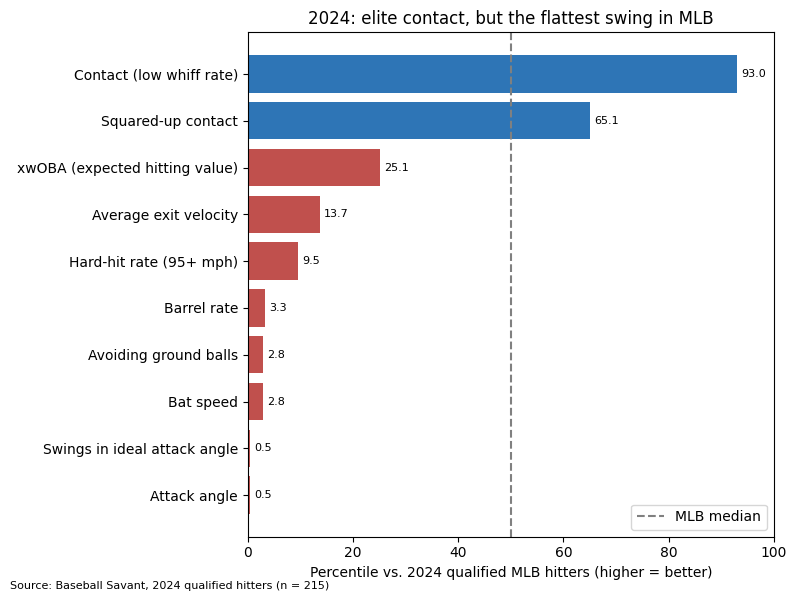

In [34]:
# he scouting report: Turang's 2024 percentile profile

#This is the main picture of the step. One horizontal bar per metric, all on the same 0–100 scale, with a dashed line at 50 for the MLB median. A long bar is good; a short bar is a gap. I leave out swing length and swing tilt, since they describe the swing's shape rather than good or bad, and I give each metric a plain-English label so a coach can read it without a glossary.

# STEP 5.5 — Percentile profile chart
import matplotlib.pyplot as plt
labels = {"attack_angle": "Attack angle",
          "ideal_attack_angle_rate": "Swings in ideal attack angle",
          "avg_bat_speed": "Bat speed",
          "gb_rate": "Avoiding ground balls",
          "brl_percent": "Barrel rate",
          "ev95percent": "Hard-hit rate (95+ mph)",
          "avg_hit_speed": "Average exit velocity",
          "est_woba": "xwOBA (expected hitting value)",
          "squared_up_per_bat_contact": "Squared-up contact",
          "whiff_per_swing": "Contact (low whiff rate)"}
chart_data = profile.drop(["swing_length", "swing_tilt"])["percentile"].rename(index=labels)
fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#c0504d" if v < 50 else "#2e75b6" for v in chart_data.values]
bars = ax.barh(chart_data.index, chart_data.values, color=colors)
ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8)
ax.axvline(50, color="gray", linestyle="--", label="MLB median")
ax.set_xlim(0, 100)
ax.set_xlabel("Percentile vs. 2024 qualified MLB hitters (higher = better)")
ax.set_title("2024: elite contact, but the flattest swing in MLB")
ax.legend(loc="lower right")
fig.text(0.01, 0.01, "Source: Baseball Savant, 2024 qualified hitters (n = 215)", fontsize=8)
plt.tight_layout()
fig.savefig(PROJECT / "outputs" / "charts" / "step05_percentile_profile_2024.png", dpi=150)
plt.show()

#Red bars are below the MLB median, and blue bars are above it.The chart i have created provides a detailed percentile profile for Turang's 2024 performance, highlighting his strengths and weaknesses in various aspects of his game. Here's a breakdown of the key findings:

### What i found

In 2024, Turang ranked last of 215 qualified hitters on attack angle and on the share of swings in the ideal attack angle window (0.5th percentile), and near the bottom on bat speed (2.8th percentile). His barrel rate was in the 3.3rd percentile, and he hit more ground balls than 97% of the league. At the same time, his contact was elite: his whiff rate beat 93% of qualified hitters, and his squared-up rate was above average (65th percentile). The shortest bars in the chart all describe the same thing: a swing that is too slow and too flat to turn good contact into damage.

What I'd check next: Which of those gaps is the #1 thing to fix? Bat speed and attack angle are both near the bottom, so the percentiles alone can't choose between them. Next, I test which one is more closely tied to barrels and xwOBA across the whole league.

### Step 6 

Step 5 showed two big gaps: bat speed and attack angle. Both are near the bottom of the league, so the percentiles alone can't tell me which one to fix first. A player can only work on one main thing at a time, so this step makes that call.

I use the 2024 league to ask one question: across all 215 hitters, which of the two goes more closely with damage, meaning barrels and xwOBA? I plot each one against barrel rate, mark Turang on each chart, and put a number on each relationship. Then I make the decision as a coach, combining what the data shows with what I know about training a swing.

In [35]:
#Attack angle vs. barrels: Each gray dot is one 2024 qualified hitter: attack angle across, barrel rate up. Turang is the red dot. If the gray dots rise from left to right, hitters with steeper swings tend to barrel more, and Turang's spot on the far left shows how far he'd have to move.

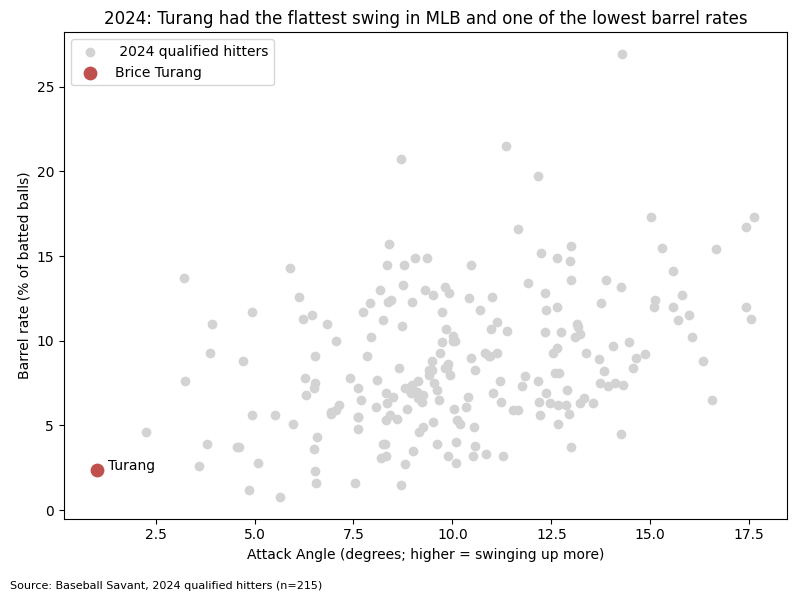

In [36]:
turang = lg24[lg24["player_id"] == 668930 ]
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(lg24["attack_angle"], lg24["brl_percent"], color= "lightgray", label=" 2024 qualified hitters")
ax.scatter(turang["attack_angle"], turang["brl_percent"], color= "#c0504d", s=80 , label= "Brice Turang")
ax.annotate("Turang", (turang["attack_angle"].iloc[0], turang["brl_percent"].iloc[0]), xytext=(8,0), textcoords="offset points")
ax.set_xlabel("Attack Angle (degrees; higher = swinging up more)")
ax.set_ylabel("Barrel rate (% of batted balls)")
ax.set_title("2024: Turang had the flattest swing in MLB and one of the lowest barrel rates")
ax.legend()
fig.text(0.01, 0.01, "Source: Baseball Savant, 2024 qualified hitters (n=215)", fontsize= 8)
plt.tight_layout(rect=[0, 0.03, 1, 1])
fig.savefig(PROJECT / "outputs" / "charts" / "step06_attack_angle_vs_barrels.png", dpi=150)
plt.show()

# Across 2024 qualified hitters, steeper swings tend to go with more barrels, but the link is loose: at a 10° attack angle, barrel rates range from about 2% to over 20%. One pattern is sharp, though: almost no hitter with an attack angle under 5° barrels more than about 8% of his batted balls. Turang sits alone in the bottom-left corner, at 1.0° and 2.4%. His swing is so flat that even a modest increase in attack angle would move him out of the zone where barrels are rare.

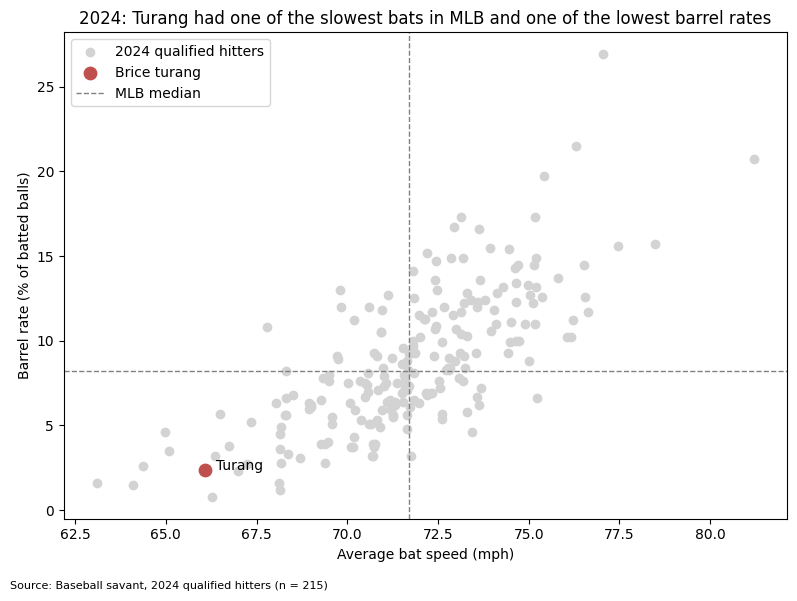

In [37]:
# Bat speed vs. barrels. The same question for the second gap: do hitters with faster bats barrel more? Same chart as 6.1, with bat speed across instead of attack angle. Comparing the two clouds shows which relationship looks tighter: the one where the dots rise most clearly from left to right.

fig, ax = plt.subplots (figsize=(8, 6))
ax.scatter(lg24["avg_bat_speed"], lg24["brl_percent"], color="lightgray", label="2024 qualified hitters")
ax.scatter(turang["avg_bat_speed"], turang["brl_percent"], color = "#c0504d", s=80, label="Brice turang")
ax.annotate("Turang", (turang["avg_bat_speed"].iloc[0], turang["brl_percent"].iloc[0]),
            xytext=(8, 0), textcoords="offset points")
ax.axvline(71.7, color="gray", linestyle="--", linewidth= 1, label="MLB median")
ax.axhline(8.2, color= "gray", linestyle="--", linewidth= 1)
ax.set_xlabel("Average bat speed (mph)")
ax.set_ylabel("Barrel rate (% of batted balls)")
ax.set_title("2024: Turang had one of the slowest bats in MLB and one of the lowest barrel rates")
ax.legend()
fig.text(0.01, 0.01, "Source: Baseball savant, 2024 qualified hitters (n = 215)", fontsize=8)
plt.tight_layout(rect=[0, 0.03, 1, 1])
fig.savefig(PROJECT / "outputs" / "charts" / "step06_bat_speed_vs_barrels.png", dpi=150)
plt.show()

# Bat speed and barrel rate rise together more tightly than attack angle and barrel rate did: the dots form a clear band from slow bats with few barrels to fast bats with many. Below about 68 mph, almost no qualified hitter barrels more than 5% of his batted balls. Turang (66.1 mph, 2.4%) sits in that slow, low-barrel group. Visually, bat speed looks like the stronger link to damage. The next cell checks that with numbers.

In [38]:
#Putting a number on each relationship. The two charts suggest bat speed is more tightly linked to barrels than attack angle is. A correlation turns each relationship into one number from −1 to 1. I check three swing metrics (bat speed, attack angle, ideal attack angle rate) against two measures of damage (barrel rate and xwOBA), all across 2024 qualified hitters.

swing_metrics = ["avg_bat_speed", "attack_angle", "ideal_attack_angle_rate"]
outcome_metrics = ["brl_percent", "est_woba"]
corr = lg24[swing_metrics + outcome_metrics].corr()
corr.loc[swing_metrics,outcome_metrics].round(2)

# Across 2024 qualified hitters, bat speed is the swing metric most tied to damage: a strong correlation with barrel rate (0.73) and a moderate one with xwOBA (0.49). Attack angle is moderately tied to barrels (0.36) but not to overall value (−0.01), likely because steeper swings also bring more whiffs and pop-ups. Ideal attack angle rate shows almost no relationship with either (0.09, −0.07). One caution: correlation only measures straight-line links, and attack angle likely has a "best range" rather than "more is better," so these numbers may understate how much an extreme case like Turang's 1.0° holds him back.

,brl_percent,est_woba
avg_bat_speed,0.73,0.49
attack_angle,0.36,-0.01
ideal_attack_angle_rate,0.09,-0.07


### Decision

**Candidate priorities:**
Bat speed: 66.1 mph (2.8th percentile). Strongest link to damage across 2024 hitters: 0.73 with barrel rate, 0.49 with xwOBA.
Attack angle: 1.0° (0.5th percentile, last in MLB). Moderate link to barrels (0.36), but none to overall value (−0.01).
 Ground-ball rate: 53.7% (2.8th percentile, flipped). This is a result of the slow, flat swing rather than a separate skill, so it should improve when the swing does.

The #1 priority: Swing faster. Add bat speed so the solid contact he already makes turns into hard-hit balls and extra-base hits.

Evidence:
Across 2024 qualified hitters, bat speed has the strongest link to barrels of any swing metric (0.73), almost twice attack angle's (0.36).

 Bat speed is also the only swing metric tied to overall value: 0.49 with xwOBA, vs. −0.01 for attack angle.
 Below about 68 mph, almost no qualified hitter barrels more than 5% of his batted balls. Turang swings 66.1 mph.

Why this one first, from a coaching view: Exit velocity starts with bat speed: as a rule of thumb, every extra mph of bat speed adds roughly 1.2–1.5 mph of exit velocity. If he steepened his swing first, without more speed, he would turn ground balls into soft fly balls, not doubles and home runs. Attack angle is the second priority. Once the bat is faster, posture, hip hinge and space drills can raise his path, using short-bat, long-bat and overload/underload bat work, plyo balls and machine work, measured with video, Blast Motion and force plates. Other tools like smash bat with smash balls would help as well. 

What we protect: His contact. Across 2024 hitters, faster bats go with more whiffs (correlation 0.54), so adding speed carries a real risk to his best skill. His whiff rate (13.8% in 2024) is the guardrail: we track it through every phase, and Step 7 sets the line it shouldn't cross.

What I found: Bat speed is Turang's #1 thing to fix. It has the strongest link to barrels (0.73) and the only link to overall value (0.49) among the swing metrics, and his 66.1 mph sits near the bottom of MLB. Attack angle comes second, once there's speed behind the swing. The risk is his contact, so his whiff rate is the number we protect.

### STEP 7- THE PLAN and GOALS 


**The question:** What numbers, by when, would show the priority is fixed?

**Why it matters:** "Swing faster" can't be checked. "Bat speed from 66.1 to 70+ mph in games by the end of 2025" can. Measurable goals are what make a plan a plan.

#### 🎯 Goal 1: Bat speed (main goal)
**66.1 mph ->70+ mph** in games by the end of 2025
Why: gets him out of the league's bottom quarter (70.4 mph).

#### 🎯 Goal 2: Attack angle
**1.0° -> 9–12°** by the end of 2025
Why: the range where most big-league hitters swing (league average: 9.9°).

#### 📈 Goal 3: Barrel rate (the result)
**2.4% -> 5%+** by the end of 2025
Why: more than double his 2024 rate.

#### 🛡️ Guardrail: Whiff rate
**13.8% -> stays under 23%**, checked every month
Why: some extra misses are fine, but past league average (23.2%), we adjust the plan.

**How the goals are measured:** Bat speed counts in games, against live pitching (Statcast), not just in front toss, batting practice or the machine. Practice numbers (Blast Motion) track progress between games, but the goal is only met when the speed shows up against real pitchers.

**Why the guardrail is whiff rate:** A faster swing can tempt a hitter to chase pitches he can't handle, and chasing shows up as more misses. Across 2024 hitters, faster bats already go with more whiffs (correlation 0.54). So whiff rate is the early warning: some increase is expected and acceptable, but past 23% (league average), his contact stops being an advantage, and we adjust the plan.

**What I found:**
- **Bat speed:** "Get your bat speed into the 70s in games, at least 4 mph faster than last year."
- **Swing path:** "Swing up through the ball more: from almost flat (1°) to the same range as most big-league hitters (9–12°)."
- **Results:** "Turn that speed and path into damage: barrel at least 5% of your batted balls, more than double last year."
- **Guardrail:** "Some extra misses are fine, but keep your whiff rate under 23%. If it goes past that, we adjust before your contact is gone."

## Step 8: What's the drill plan?

**The question:** Which drills, how often, and in what order will move his bat speed and swing path?

**Why it matters:** The data found the problem. Drills fix it. This is the plan a hitting coach could pick up and run on Monday.

### Before any work: measure everything (Day 1 of the off-season)

- **In the cage:** bat speed and attack angle with Blast Motion. Force plates to see how he uses the ground: is he loading his back heel, and is the force moving all the way into his front foot? Motion capture to see the full skeleton of his swing, including hip-shoulder separation.
- **In the weight room:** bar speed on key lifts with a bar sensor, plus VALD ForceDecks tests: squat jump, drop jump and isometric mid-thigh pull.

These numbers become his starting line, and I retest them at the end of each phase.

### Phase 1: Off-season (building the speed and the path)

**The weekly rhythm:**

| Day | Focus |
|---|---|
| 1 | Bat speed |
| 2 | Bat-to-ball (swing path / attack angle) |
| 3 | Bat speed |
| 4 | Bat-to-ball (swing path / attack angle) |
| 5 | Competition: live at-bats (live pitchers or Trajekt) |

**Bat speed days**

1. **Warm-up:** offset rotation drills (open, closed and neutral stance). 1 set of 4 swings with each speed-trainer bat, off a tee or front toss.
2. **Drills that target his flat swing:**

| Drill | Bat | Ball | Setup |
|---|---|---|---|
| Offset open | Bazooka bat (Driveline) | Plyo balls | Front toss |
| Step back | Short bat | Plyo balls | Front toss |
| Step behind | Long bat | Plyo balls and baseballs | Front toss |

3. **The real work:** the same three drills on the machine or in BP, now with the speed-trainer bats: 4 sets of 4 swings with each bat.
4. **Finish with the game bat:** normal stance, game-like pitches.
5. **Every swing is measured** with Blast Motion.

**Bat-to-ball days**

- The same flaw drills, balls and setup as the bat speed days, with the speed trainers.
- After the first bat-to-ball day, I add drills for whatever new flaws the data shows: posture, hip hinge and separation, still combined with the speed trainers.
- Finish with game swings: the machine or short-distance BP, as game-like as possible.

**Competition day**

- Three "feel" drills that help him find his best swing quickly, with only a light load on the speed trainers.
- Then live at-bats. The goal is to compete, not to think. He should swing freely, not get stuck in his head about mechanics.

### Phase 2: Spring (taking it to live pitching)

- Keep the bat speed he built, or add a little, without wearing out his arms: fewer swings and fewer speed-trainer days.
- Narrow the work down to 5 drills that give him his best feel.
- Keep checking for any flaw that's left, and keep the load low enough that he doesn't show up to games tired.

### Phase 3: In-season (keeping it)

- A short routine built on at least 3 go-to drills he can always count on to get his good swing back, especially when he's struggling.

### What could go wrong, and the fix

| Risk | What I'd see | What I do |

| He whiffs more | Whiff rate climbing toward 23% | Check his other numbers first. If barrels and xwOBA are up, the trade is working, so I keep going. If his whiff rate passes 23%, I scale back the speed work and go back to his feel drills. |
| His swing gets too steep | Attack angle above the 12° target, and more misses on high fastballs | Bring the path back into the 9–12° range with his flatter-path drills, and track how he does on high fastballs. |
| He gets tired | Bat speed dropping session to session, or ForceDecks numbers falling | Cut swing volume and speed-trainer days until his numbers recover. |

**What I found:** The plan builds speed and path together: two bat speed days, two bat-to-ball days and one competition day a week, with every swing measured. In spring, the volume drops so he stays fresh, and in-season he keeps three go-to drills to find his swing fast. The two things I watch most closely are his whiff rate and an attack angle that gets too steep, because either one can cost him the contact that keeps him in the lineup.

### what Step 9 is about

Everything up to now used only 2024, the way a PD analyst would have after that season. Now I open the two seasons that came after it, 2025 and 2026, and check the plan against what actually happened.

This is the part most development plans never get: a real test. I'll score every goal from Step 7 as met or missed, with the number, and I'll be honest about both. If he hit the bat speed goal but gave away too much contact, the scorecard has to say so.

In [39]:
#Four seasons side by side. One table with his swing and his results for every season: 2023 (context, 2nd half only for swing metrics), 2024 (the baseline the plan was built on), and 2025–2026 (the test).

season_cols = ["avg_bat_speed", "attack_angle", "ideal_attack_angle_rate", "swing_length", "whiff_per_swing", "brl_percent", "est_woba", "woba"]
turang_seasons = league[league["player_id"] == 668930].set_index("season")[season_cols]
print(turang_seasons.round(3))

#After 2024, his swing changed in the direction the plan called for. Bat speed rose from 66.1 to 70.6 mph in 2025 and held at 70.1 in 2026, and his barrel rate more than tripled (2.4% -> 7.9%). His attack angle climbed from 1.0° to 6.9° and then 8.6°, a big change but still short of the 9–12° target. The cost was contact: his whiff rate rose from 13.8% to 18.9% and then 21.4%, still under the 23% guardrail but getting close. Overall, his expected hitting value (xwOBA) rose from .302 to .344. One caution: 2024 was his low point. In the second half of 2023 he already swung 68.4 mph at 5.2°, so part of the 2025 jump was a return to his earlier level.

        avg_bat_speed  attack_angle  ideal_attack_angle_rate  swing_length  \
season                                                                       
2023           68.390         5.203                    0.392         6.505   
2024           66.068         1.014                    0.258         6.069   
2025           70.632         6.926                    0.450         6.827   
2026           70.088         8.554                    0.488         6.782   

        whiff_per_swing  brl_percent  est_woba   woba  
season                                                 
2023              0.173          2.9     0.275  0.262  
2024              0.138          2.4     0.302  0.294  
2025              0.189          7.9     0.335  0.346  
2026              0.214          7.7     0.344  0.358  


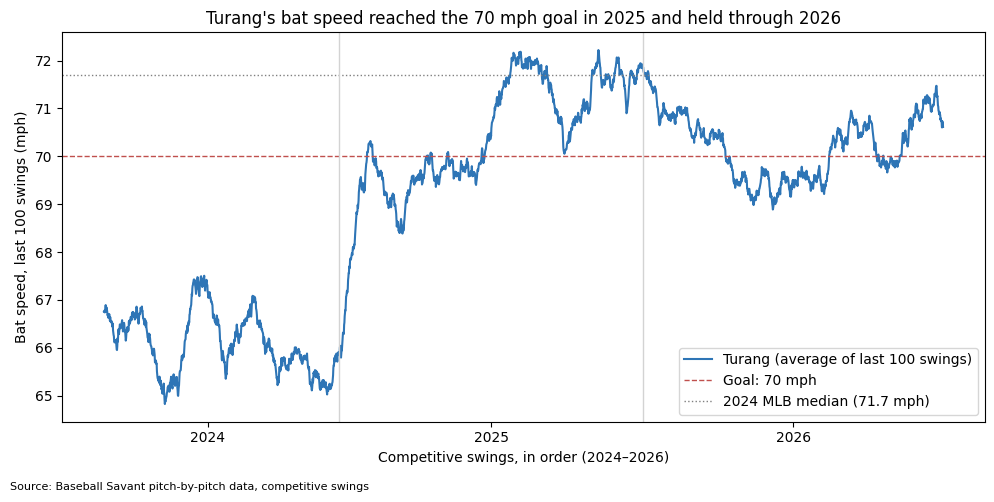

In [40]:
#When did his bat speed change? Season averages hide timing. Did the speed show up on Opening Day 2025, build slowly through the year, or fade by 2026? A rolling average answers that: the average of his last 100 swings, recalculated after every new swing, so the line follows his swing over time instead of jumping from one season to the next.

roll = (swing_comp[swing_comp["game_year"] >= 2024]
        .sort_values(["game_date", "at_bat_number", "pitch_number"])
        .reset_index(drop=True))
roll["bat_speed_100"] = roll["bat_speed"].rolling(100).mean()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(roll.index, roll["bat_speed_100"], color="#2e75b6", label="Turang (average of last 100 swings)")
ax.axhline(70, color="#c0504d", linestyle="--", linewidth=1, label="Goal: 70 mph")
ax.axhline(71.7, color="gray", linestyle=":", linewidth=1, label="2024 MLB median (71.7 mph)")
ax.axvline((roll["game_year"] < 2025).sum(), color="lightgray", linewidth=1)
ax.axvline((roll["game_year"] < 2026).sum(), color="lightgray", linewidth=1)
ax.set_xticks([465, 1466, 2533], ["2024", "2025", "2026"])
ax.set_xlabel("Competitive swings, in order (2024–2026)")
ax.set_ylabel("Bat speed, last 100 swings (mph)")
ax.set_title("Turang's bat speed reached the 70 mph goal in 2025 and held through 2026")
ax.legend(loc="lower right")
fig.text(0.01, 0.01, "Source: Baseball Savant pitch-by-pitch data, competitive swings", fontsize=8)
plt.tight_layout(rect=[0, 0.03, 1, 1])
fig.savefig(PROJECT / "outputs" / "charts" / "step09_rolling_bat_speed.png", dpi=150)
plt.show()

### As we can see. His bat speed didn't build slowly. It jumped right at the start of 2025, from around 65–67 mph through 2024 to over 70 within the first weeks of the season. That timing points to off-season work, which is when Phase 1 of my plan happens. By mid-2025 his last-100-swing average reached about 72 mph, above the league median. It dipped to around 69 mph late in 2025 and early in 2026, then climbed back to about 71. That dip is bigger than chance alone would explain, and it's the kind of late-season fatigue my plan watches for.

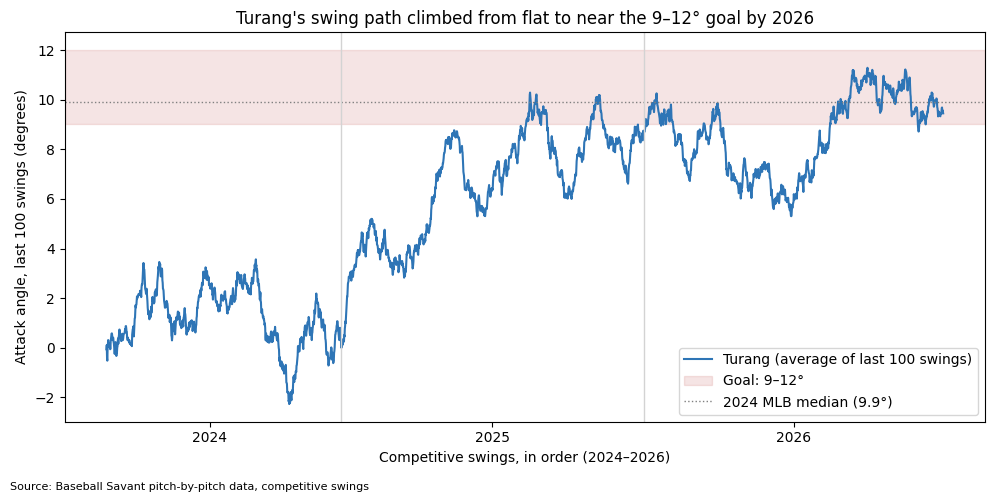

In [41]:
#When did his swing path change?. Same view for the second goal: his attack angle, averaged over his last 100 swings. The goal is a range, not a single line, so I shade the 9–12° band from Step 7. If the line enters the band and stays there, the goal was met. I also want to see whether the path changed at the same moment as the bat speed, or on its own schedule.

roll["attack_angle_100"] = roll["attack_angle"].rolling(100).mean()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(roll.index, roll["attack_angle_100"], color="#2e75b6", label="Turang (average of last 100 swings)")
ax.axhspan(9, 12, color="#c0504d", alpha=0.15, label="Goal: 9–12°")
ax.axhline(9.9, color="gray", linestyle=":", linewidth=1, label="2024 MLB median (9.9°)")
ax.axvline((roll["game_year"] < 2025).sum(), color="lightgray", linewidth=1)
ax.axvline((roll["game_year"] < 2026).sum(), color="lightgray", linewidth=1)
ax.set_xticks([465, 1466, 2533], ["2024", "2025", "2026"])
ax.set_xlabel("Competitive swings, in order (2024–2026)")
ax.set_ylabel("Attack angle, last 100 swings (degrees)")
ax.set_title("Turang's swing path climbed from flat to near the 9–12° goal by 2026")
ax.legend(loc="lower right")
fig.text(0.01, 0.01, "Source: Baseball Savant pitch-by-pitch data, competitive swings", fontsize=8)
plt.tight_layout(rect=[0, 0.03, 1, 1])
fig.savefig(PROJECT / "outputs" / "charts" / "step09_rolling_attack_angle.png", dpi=150)
plt.show()

##His swing path changed on a different schedule than his bat speed. Bat speed jumped right at the start of 2025, while his attack angle climbed gradually through the first half of the season, from about 1° to 8–10°. That order (speed first, path second) matches the plan. He reached the 9–12° goal band in mid-2025 but slipped back to about 6° late in the season, the same stretch where his bat speed dipped, which suggests one shared cause, such as fatigue. By late 2026 his attack angle was back inside the band, around 10–11°.

In [ ]:
# Did the plan work? Every goal from Step 7, scored against what actually happened. I use full-season averages, since that's what the goals were written for, and mark each one met or missed for 2025 and 2026. No rounding up and no excuses: if a goal was missed, the scorecard says so.
s24 = turang_seasons.loc[2024]
s25 = turang_seasons.loc[2025]
s26 = turang_seasons.loc[2026]
goal_cols = ["avg_bat_speed", "attack_angle", "brl_percent", "whiff_per_swing"]
scorecard = pd.DataFrame({
    "goal" : ["Bat Speed(mph)", "Attack Angle(Degrees)", "Barrel rate (%)", "Whiff rate (guardrail)"],
    "target": ["70+", "9-12", "5+", "under 0.23"],
    "2024": s24[goal_cols].values,
    "2025": s25[goal_cols].values,
    "2026": s26[goal_cols].values})
scorecard["met_2025"] = [s25["avg_bat_speed"] >= 70,
                         9 <= s25["attack_angle"]<= 12,
                         s25["brl_percent"] >= 5,
                         s25["whiff_per_swing"] <0.23]
scorecard["met_2026"] = [s26["avg_bat_speed"] >=70,
                         9 <= s26["attack_angle"] <= 12,
                         s26["brl_percent"]>= 5,
                         s26["whiff_per_swing"] < 0.23]
scorecard.round(3)

### Wrapping up Step 9

## What I found: The plan pointed in the right direction. His bat speed jumped about 4.5 mph right at the start of 2025 and held, his barrel rate more than tripled, and his expected hitting value moved from the bottom quarter of the league to the top quarter (.302 -> .344). His swing path followed more slowly than I targeted: 9–12° was too fast a timeline for one season, and he only reached that range late in 2026. The cost was contact, with his whiff rate up from 13.8% to 21.4%, but it stayed under my 23% guardrail. But we can see that by improving Barrel path you are more productive for your team. 

,goal,target,2024,2025,2026,met_2025,met_2026
0,bat speed (mph),70+,66.068,70.632,70.088,True,True
1,Attack Angle(Degrees),9-12,1.014,6.926,8.554,False,False
2,Barrel rate (%),5+,2.400,7.900,7.700,True,True
3,Whiff rate (guardrail),under 0.23,0.138,0.189,0.214,True,True


 ### what Step 10 is about?

The analysis is done. Now it has to reach people, and different people need different things from the same finding:
- **A player** needs one goal and the work to get there.
- **A hitting coach** needs the plan: drills, phases and what to watch.
- **A PD director** needs the evidence: what was wrong, why this fix, and proof it worked.

This step builds one hero chart that tells the whole story in a single picture, then outlines the three deliverables that come from it: a one-pager (English and Spanish), a short deck and the README. Every number in them comes from this notebook

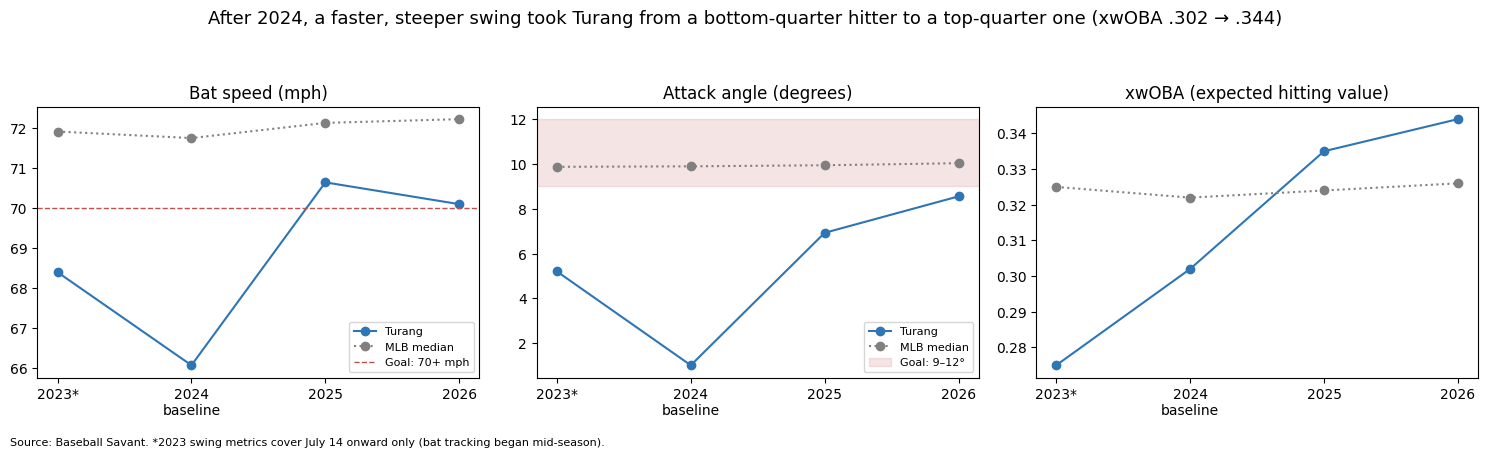

In [ ]:
# STEP 10.1 — Hero chart


years = turang_seasons.index

# One row of three panels that share the same x-axis
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True)

# Panel 1: bat speed (Turang, league median, goal line)
ax1.plot(years, turang_seasons["avg_bat_speed"],
         marker="o", color="#2e75b6", label="Turang")
ax1.plot(years, medians["avg_bat_speed"],
         marker="o", color="gray", linestyle=":", label="MLB median")
ax1.axhline(70, color="#c0504d", linestyle="--", linewidth=1,
            label="Goal: 70+ mph")
ax1.set_title("Bat speed (mph)")
ax2.plot(years, turang_seasons["attack_angle"],
         marker="o", color="#2e75b6", label="Turang")
ax2.plot(years, medians["attack_angle"],
         marker="o", color="gray", linestyle=":", label="MLB median")
ax2.axhspan(9, 12, color="#c0504d", alpha=0.15, label="Goal: 9–12°")
ax2.set_title("Attack angle (degrees)")
ax3.plot(years, turang_seasons["est_woba"],
         marker="o", color="#2e75b6", label="Turang")
ax3.plot(years, medians["est_woba"],
         marker="o", color="gray", linestyle=":", label="MLB median")
ax3.set_title("xwOBA (expected hitting value)")


for ax in [ax1, ax2, ax3]:
    ax.set_xticks([2023, 2024, 2025, 2026],
                  ["2023*", "2024\nbaseline", "2025", "2026"])
ax1.legend(fontsize=8)
ax2.legend(fontsize=8)
fig.suptitle("After 2024, a faster, steeper swing took Turang from a "
             "bottom-quarter hitter to a top-quarter one (xwOBA .302 → .344)",
             fontsize=13)
fig.text(0.01, 0.01,
         "Source: Baseball Savant. *2023 swing metrics cover July 14 onward "
         "only (bat tracking began mid-season).",
         fontsize=8)
plt.tight_layout(rect=[0, 0.04, 1, 0.92])
fig.savefig(PROJECT / "outputs" / "charts" / "step10_hero_swing_change.png", dpi=150)
plt.show()

### One chart tells the whole arc: all three lines drop in 2024 and jump in 2025. His bat speed passed the 70 mph goal, his attack angle climbed toward the 9–12° band, and his expected hitting value (xwOBA) went from below the league median to well above it. The most interesting part: in 2026 his bat speed and attack angle were still below the league median, yet his xwOBA was well above it. He didn't need an average swing to become an above-average hitter, just a good-enough swing on top of the elite contact he already had.